# Exploration and preprocessing

1. **Data visualization**: class balance, missing values, correlations, heart-disease rate by category, distributions by class.
2. **Preprocessing steps**: effect of each cleaning / feature-engineering step on the validation F1.

# Part 1 - Data visualization
(from `visualization.ipynb`)

# Data visualization (EDA)

Exploratory plots of the BRFSS training set:

1. Class balance
2. Missing values per column
3. Features most correlated with heart disease
4. Heart-disease rate by category (age, general health, blood pressure, ...)
5. Distributions of continuous features, healthy vs. sick
6. Correlations between the top features

Plots use the **cleaned** data from `preprocessing.py` (special codes such as 7/9/77/99 are already turned into NaN).
Set `SAVE_FIGS = True` to also save each figure as a PDF in `figures/` (for the LaTeX report).

In [1]:
import csv
import os

import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data
from preprocessing import compute_groups, clean, fit_column_filter

DATA_PATH = "data/dataset"
SAVE_FIGS = False
FIG_DIR = "figures"

# Colors: one fixed color per class, used in every plot
HEALTHY = "#2a78d6"   # blue   -> no heart disease
SICK = "#eb6834"      # orange -> heart disease
NEUTRAL = "#52514e"   # gray   -> reference lines / text

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "legend.frameon": False,
})


def save(fig, name):
    """Save the figure as PDF in FIG_DIR if SAVE_FIGS is True."""
    if SAVE_FIGS:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, f"{name}.pdf"), bbox_inches="tight")

## Load and clean the data

In [2]:
# Unzip the dataset if needed
if not os.path.exists(os.path.join(DATA_PATH, "x_train.csv")):
    import zipfile
    with zipfile.ZipFile("data/dataset_to_release.zip") as z:
        z.extractall("data/")

x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)

with open(os.path.join(DATA_PATH, "x_train.csv")) as f:
    names = next(csv.reader(f))[1:]   # drop "Id"

y01 = np.where(y_train == 1, 1, 0)   # -1/1 -> 0/1

# Same cleaning as the models
groups = compute_groups(x_train, names)
x_clean, kept_names = clean(x_train, names, groups)
keep = fit_column_filter(x_clean)
x_clean = x_clean[:, keep]
kept_names = [n for n, k in zip(kept_names, keep) if k]


def col(name):
    """Return a cleaned column by name."""
    return x_clean[:, kept_names.index(name)]


print("raw:", x_train.shape, " cleaned:", x_clean.shape)

raw: (328135, 321)  cleaned: (328135, 170)


## 1. Class balance
Only a small fraction of people have heart disease: accuracy alone is misleading, F1 is a better metric.

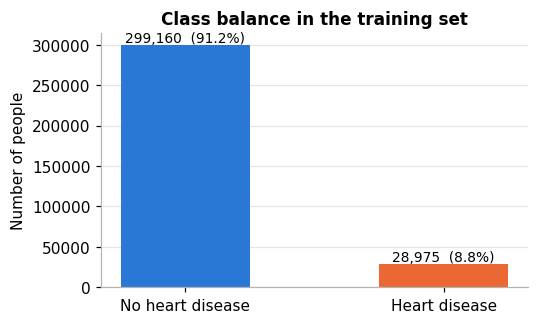

In [3]:
counts = np.array([np.sum(y01 == 0), np.sum(y01 == 1)])
labels = ["No heart disease", "Heart disease"]

fig, ax = plt.subplots(figsize=(5, 3))
bars = ax.bar(labels, counts, color=[HEALTHY, SICK], width=0.5)
for b, c in zip(bars, counts):
    ax.text(b.get_x() + b.get_width() / 2, c, f"{c:,}  ({c / counts.sum():.1%})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Number of people")
ax.set_title("Class balance in the training set")
ax.grid(axis="x", visible=False)
save(fig, "class_balance")
plt.show()

## 2. Missing values per column
Raw data, before cleaning. Many questions were only asked to a subgroup, so many columns are almost empty.

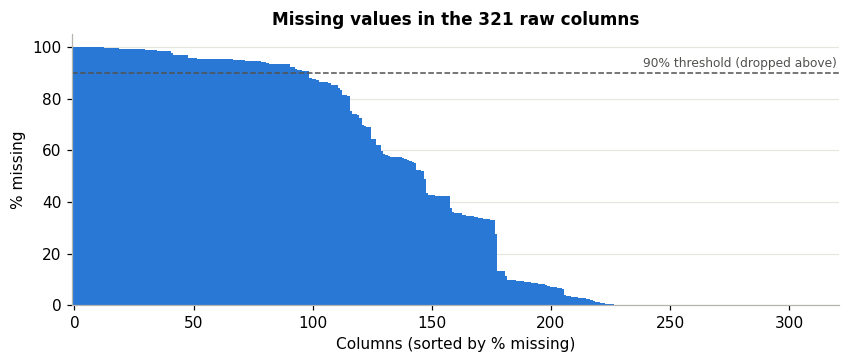

Columns with > 90% missing: 99
Columns with no missing:    82


In [4]:
nan_ratio = np.isnan(x_train).mean(axis=0)
order = np.argsort(nan_ratio)[::-1]

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(np.arange(len(order)), nan_ratio[order] * 100, width=1.0, color=HEALTHY)
ax.axhline(90, color=NEUTRAL, linestyle="--", linewidth=1)
ax.text(len(order) - 1, 91, "90% threshold (dropped above)", ha="right", va="bottom",
        fontsize=8, color=NEUTRAL)
ax.set_xlim(-1, len(order))
ax.set_xlabel("Columns (sorted by % missing)")
ax.set_ylabel("% missing")
ax.set_title(f"Missing values in the {x_train.shape[1]} raw columns")
ax.grid(axis="x", visible=False)
save(fig, "missing_values")
plt.show()

print(f"Columns with > 90% missing: {np.sum(nan_ratio > 0.9)}")
print(f"Columns with no missing:    {np.sum(nan_ratio == 0)}")

## 3. Features most correlated with heart disease
Absolute Pearson correlation between each cleaned feature (NaN filled with the mean) and the label.

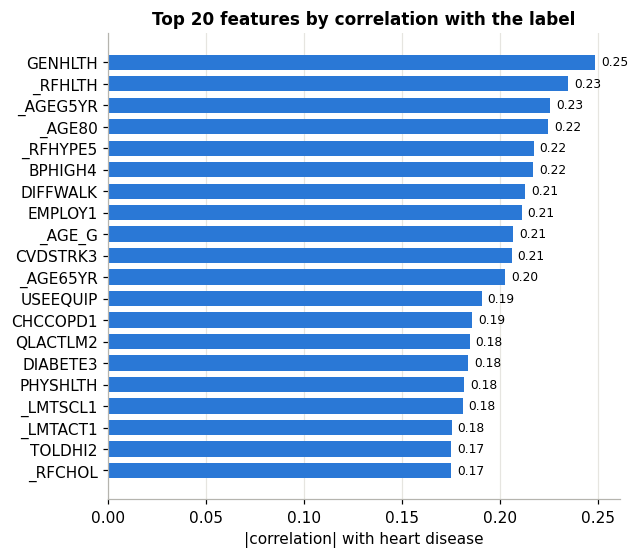

In [5]:
corrs = []
for j, name in enumerate(kept_names):
    c = x_clean[:, j].copy()
    c[np.isnan(c)] = np.nanmean(c)
    if c.std() > 0:
        corrs.append((np.corrcoef(c, y01)[0, 1], name))

corrs.sort(key=lambda t: abs(t[0]), reverse=True)
top = corrs[:20]

fig, ax = plt.subplots(figsize=(6, 5.5))
values = [abs(v) for v, _ in top][::-1]
ax.barh([n for _, n in top][::-1], values, color=HEALTHY, height=0.7)
for i, v in enumerate(values):
    ax.text(v + 0.003, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("|correlation| with heart disease")
ax.set_title("Top 20 features by correlation with the label")
ax.grid(axis="y", visible=False)
save(fig, "top_correlations")
plt.show()

## 4. Heart-disease rate by category
Share of people with heart disease in each category. The dashed line is the overall rate.

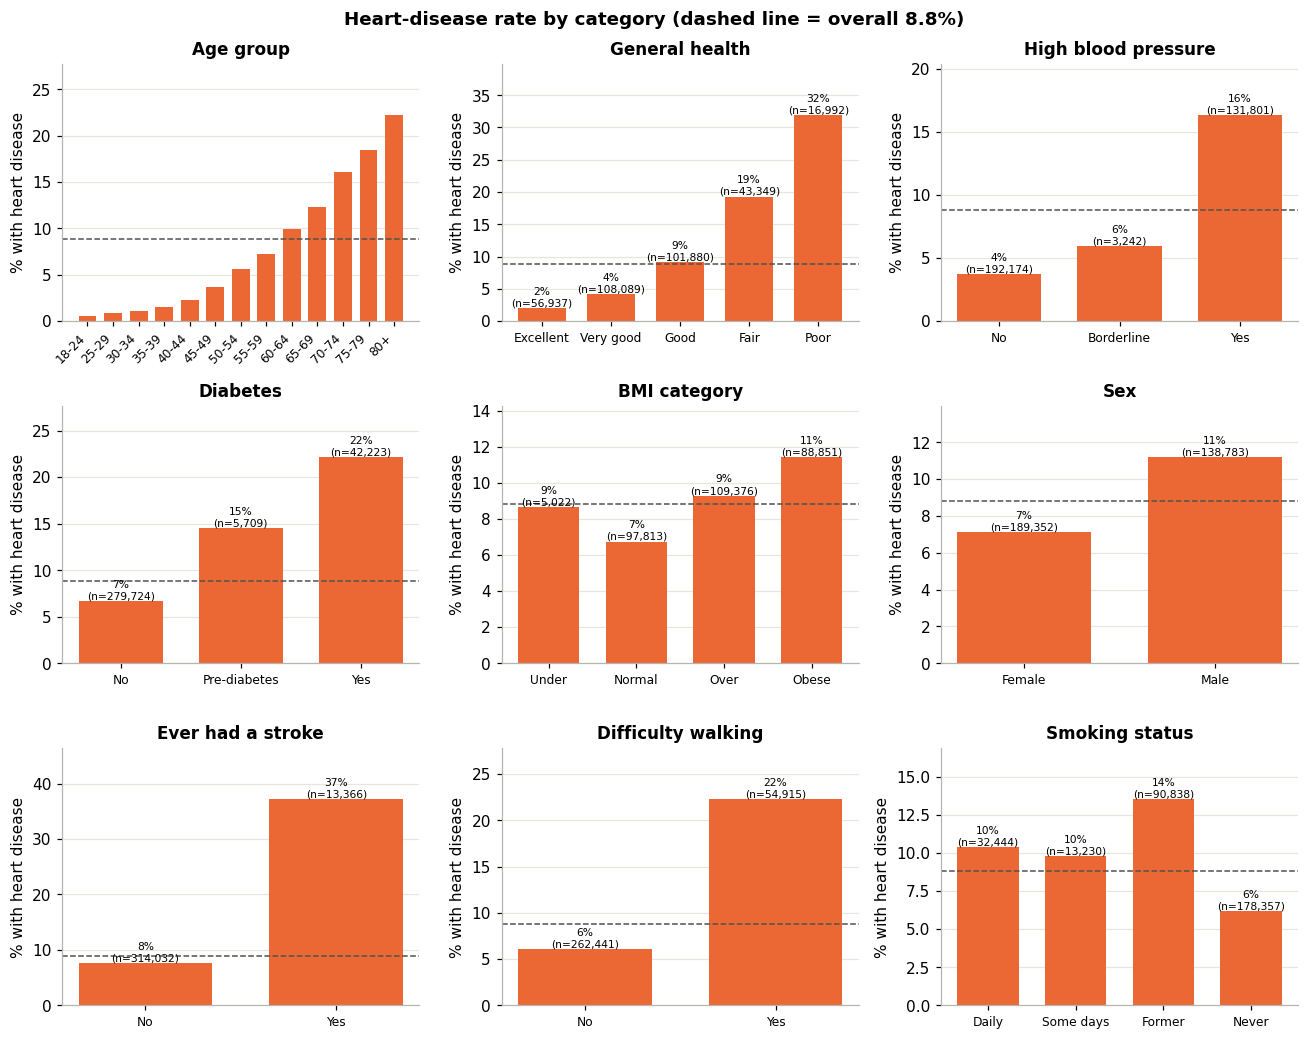

In [6]:
AGE_LABELS = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]

# column -> (title, {value: label}) ; values are after cleaning
CATEGORICAL_PLOTS = {
    "_AGEG5YR": ("Age group", {i + 1: a for i, a in enumerate(AGE_LABELS)}),
    "GENHLTH": ("General health", {1: "Excellent", 2: "Very good", 3: "Good", 4: "Fair", 5: "Poor"}),
    "BPHIGH4": ("High blood pressure", {0: "No", 0.5: "Borderline", 1: "Yes"}),
    "DIABETE3": ("Diabetes", {0: "No", 0.5: "Pre-diabetes", 1: "Yes"}),
    "_BMI5CAT": ("BMI category", {1: "Under", 2: "Normal", 3: "Over", 4: "Obese"}),
    "SEX": ("Sex", {0: "Female", 1: "Male"}),
    "CVDSTRK3": ("Ever had a stroke", {0: "No", 1: "Yes"}),
    "DIFFWALK": ("Difficulty walking", {0: "No", 1: "Yes"}),
    "_SMOKER3": ("Smoking status", {1: "Daily", 2: "Some days", 3: "Former", 4: "Never"}),
}

overall = y01.mean()
plots = [(c, t, m) for c, (t, m) in CATEGORICAL_PLOTS.items() if c in kept_names]

ncols = 3
nrows = int(np.ceil(len(plots) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows))
axes = axes.ravel()

for ax, (c, title, mapping) in zip(axes, plots):
    values = col(c)
    cats = [v for v in mapping if np.any(values == v)]
    rates = [y01[values == v].mean() * 100 for v in cats]
    sizes = [np.sum(values == v) for v in cats]

    ax.bar(range(len(cats)), rates, color=SICK, width=0.7)
    ax.axhline(overall * 100, color=NEUTRAL, linestyle="--", linewidth=1)
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels([mapping[v] for v in cats],
                       rotation=45 if len(cats) > 5 else 0,
                       ha="right" if len(cats) > 5 else "center", fontsize=8)
    ax.set_title(title)
    ax.set_ylabel("% with heart disease")
    ax.grid(axis="x", visible=False)
    if len(cats) <= 5:
        for i, (r, n) in enumerate(zip(rates, sizes)):
            ax.text(i, r, f"{r:.0f}%\n(n={n:,})", ha="center", va="bottom", fontsize=7)
    ax.set_ylim(0, max(rates) * 1.25)

for ax in axes[len(plots):]:
    ax.set_visible(False)

fig.suptitle(f"Heart-disease rate by category (dashed line = overall {overall:.1%})",
             fontweight="bold")
fig.tight_layout()
save(fig, "rate_by_category")
plt.show()

## 5. Continuous features: healthy vs. sick
Normalized histograms (each class sums to 1), so the two groups are comparable despite the class imbalance.

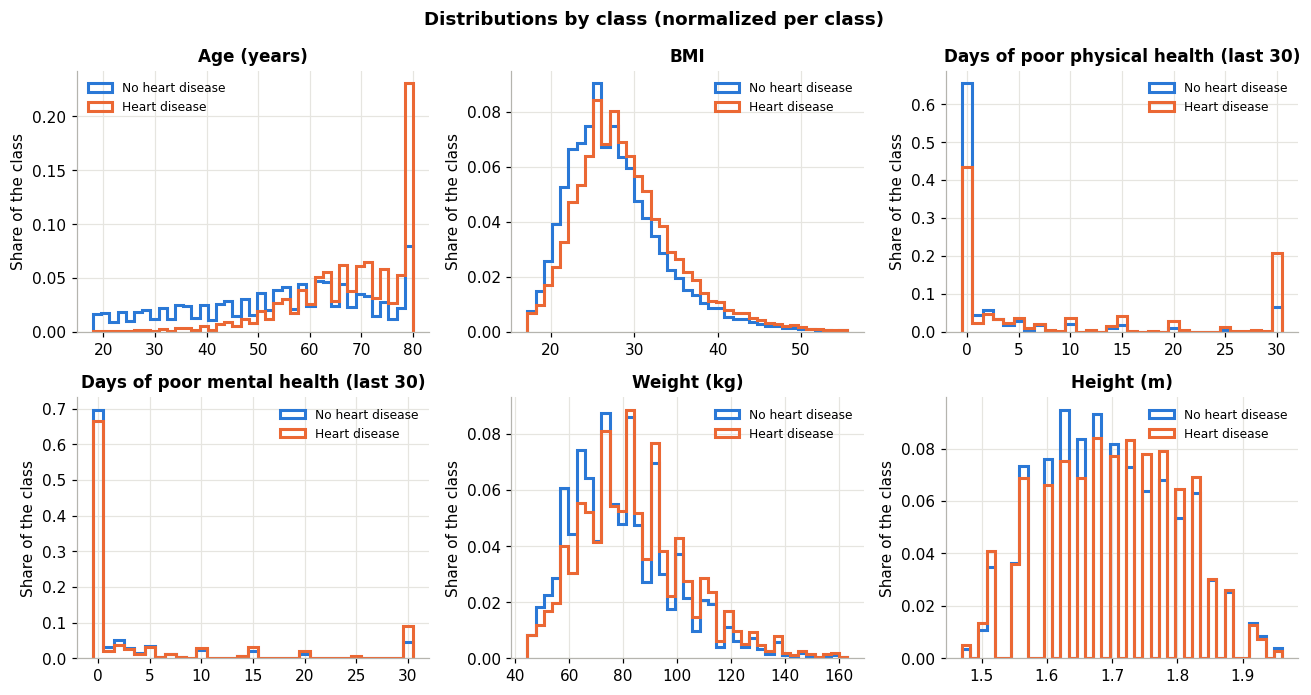

In [7]:
CONTINUOUS = {
    "_AGE80": "Age (years)",
    "_BMI5": "BMI",
    "PHYSHLTH": "Days of poor physical health (last 30)",
    "MENTHLTH": "Days of poor mental health (last 30)",
    "WTKG3": "Weight (kg)",
    "HTM4": "Height (m)",
}

plots = [(c, t) for c, t in CONTINUOUS.items() if c in kept_names]
ncols = 3
nrows = int(np.ceil(len(plots) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.2 * nrows))
axes = axes.ravel()

for ax, (c, title) in zip(axes, plots):
    values = col(c)
    ok = ~np.isnan(values)
    lo, hi = np.nanpercentile(values, [0.5, 99.5])
    bins = np.linspace(lo, hi, 40) if len(np.unique(values[ok])) > 40 else \
        np.arange(lo - 0.5, hi + 1.5)

    for cls, color, label in [(0, HEALTHY, "No heart disease"), (1, SICK, "Heart disease")]:
        v = values[ok & (y01 == cls)]
        w = np.ones_like(v) / len(v)
        ax.hist(v, bins=bins, weights=w, histtype="step", linewidth=2, color=color, label=label)

    ax.set_title(title)
    ax.set_ylabel("Share of the class")
    ax.legend(fontsize=8)

for ax in axes[len(plots):]:
    ax.set_visible(False)

fig.suptitle("Distributions by class (normalized per class)", fontweight="bold")
fig.tight_layout()
save(fig, "distributions_by_class")
plt.show()

## 6. Correlations between the top features
Redundant features (e.g. several age variables) show up as dark squares.

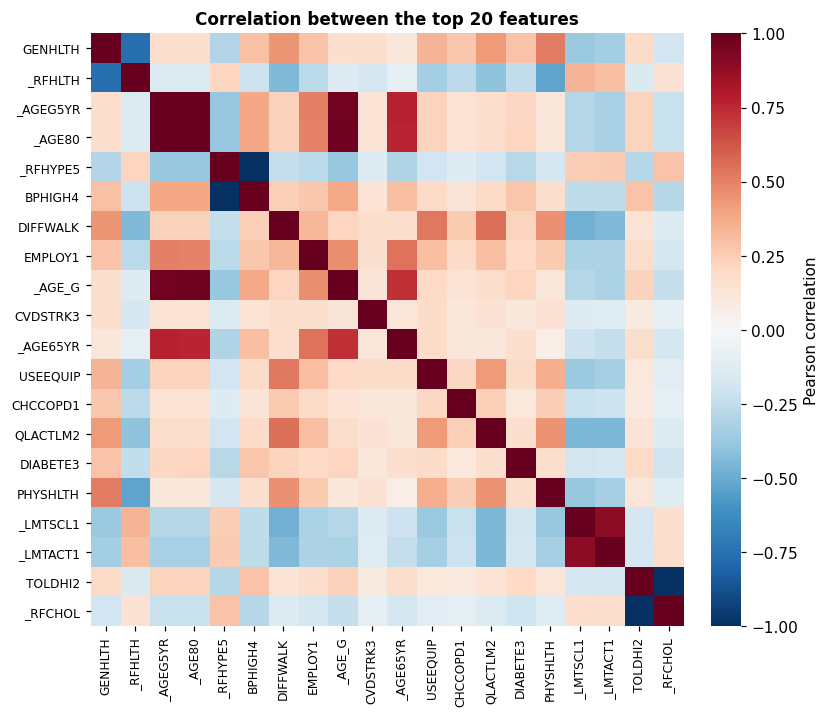

Highly correlated pairs (|r| > 0.8):
  _AGEG5YR   ~ _AGE80     r = 0.99
  _AGEG5YR   ~ _AGE_G     r = 0.97
  _AGE80     ~ _AGE_G     r = 0.97
  _RFHYPE5   ~ BPHIGH4    r = -0.99
  _LMTSCL1   ~ _LMTACT1   r = 0.90
  TOLDHI2    ~ _RFCHOL    r = -1.00


In [8]:
top_names = [n for _, n in corrs[:20]]
idx = [kept_names.index(n) for n in top_names]

sub = x_clean[:, idx].copy()
sub = np.where(np.isnan(sub), np.nanmean(sub, axis=0), sub)
corr = np.corrcoef(sub, rowvar=False)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(top_names)))
ax.set_yticks(range(len(top_names)))
ax.set_xticklabels(top_names, rotation=90, fontsize=8)
ax.set_yticklabels(top_names, fontsize=8)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson correlation")
cbar.outline.set_visible(False)
ax.set_title("Correlation between the top 20 features")
save(fig, "feature_correlations")
plt.show()

print("Highly correlated pairs (|r| > 0.8):")
for i in range(len(top_names)):
    for j in range(i + 1, len(top_names)):
        if abs(corr[i, j]) > 0.8:
            print(f"  {top_names[i]:<10} ~ {top_names[j]:<10} r = {corr[i, j]:.2f}")

## 7. Explore any column

`show_column("NAME")`: value counts and heart-disease rate for one column (cleaned values).

GENHLTH: 0.3% missing, 5 distinct values


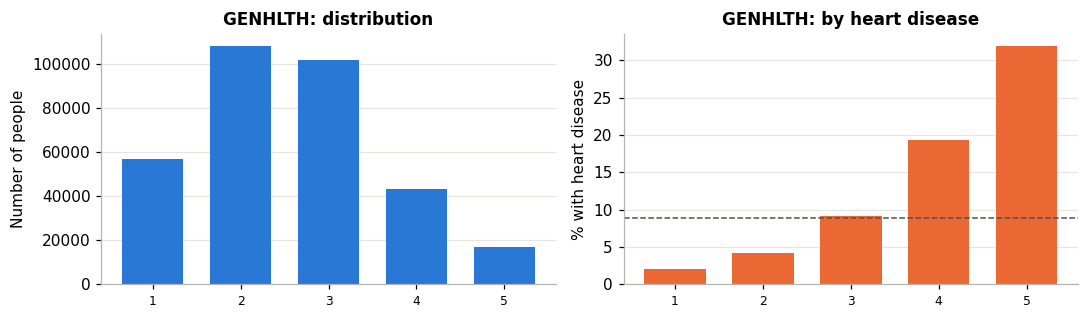

In [9]:
def show_column(name, max_cats=15):
    """Plot the distribution of a cleaned column and the heart-disease rate per value."""
    values = col(name)
    ok = ~np.isnan(values)
    uniq, cnt = np.unique(values[ok], return_counts=True)
    print(f"{name}: {np.mean(~ok):.1%} missing, {len(uniq)} distinct values")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3))
    if len(uniq) <= max_cats:
        rates = [y01[values == u].mean() * 100 for u in uniq]
        x = range(len(uniq))
        ax1.bar(x, cnt, color=HEALTHY, width=0.7)
        ax2.bar(x, rates, color=SICK, width=0.7)
        for ax in (ax1, ax2):
            ax.set_xticks(list(x))
            ax.set_xticklabels([f"{u:g}" for u in uniq], fontsize=8)
            ax.grid(axis="x", visible=False)
        ax2.axhline(y01.mean() * 100, color=NEUTRAL, linestyle="--", linewidth=1)
        ax1.set_ylabel("Number of people")
        ax2.set_ylabel("% with heart disease")
    else:
        bins = np.linspace(*np.nanpercentile(values, [0.5, 99.5]), 40)
        ax1.hist(values[ok], bins=bins, color=HEALTHY)
        ax1.set_ylabel("Number of people")
        for cls, color, label in [(0, HEALTHY, "No heart disease"), (1, SICK, "Heart disease")]:
            v = values[ok & (y01 == cls)]
            ax2.hist(v, bins=bins, weights=np.ones_like(v) / len(v), histtype="step",
                     linewidth=2, color=color, label=label)
        ax2.set_ylabel("Share of the class")
        ax2.legend(fontsize=8)
    ax1.set_title(f"{name}: distribution")
    ax2.set_title(f"{name}: by heart disease")
    fig.tight_layout()
    plt.show()


show_column("GENHLTH")

# Part 2 - Preprocessing steps and their effect on F1
(from `baseline.ipynb`: raw → cleaning → one-hot → NaN indicators → interactions, regularized logistic regression on an 80/20 split)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

from helpers import *
from implementations import *

In [2]:
import os
import zipfile

DATA_PATH = "data/"

zip_path = os.path.join(DATA_PATH, "dataset_to_release.zip")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(DATA_PATH)

print(os.listdir(DATA_PATH))

['dataset', 'dataset_to_release.zip']


In [6]:
"""
Baseline: computes the reference F1 that everyone tries to beat.
"""

import numpy as np
from preprocessing import *
from helpers import load_csv_data

# ---------------------------------------------------------------------
# Load the data: x_train, x_test, y_train (labels -1/1), names (column names)
# ---------------------------------------------------------------------
x_train, x_test, y_train, train_ids, test_ids = load_csv_data("data/dataset")

import csv
import numpy as np

with open("data/dataset/x_train.csv", "r") as f:  # read only the header line
    header = next(csv.reader(f))
names = header[1:]  # column names, without "Id"
assert len(names) == x_train.shape[1]

rows = []
for j, name in enumerate(names):
    col = x_train[:, j]
    valid = col[~np.isnan(col)]
    n_unique = len(np.unique(valid))
    rows.append([
        j, name,
        round(np.isnan(col).mean(), 3),          # share of missing values
        n_unique,                                 # number of distinct values
        valid.min() if len(valid) else "",
        valid.max() if len(valid) else "",
        round(valid.mean(), 3) if len(valid) else "",  # empty if the column has no value
        ])
    
y01 = np.where(y_train == 1, 1, 0)  # -1/1 labels -> 0/1
# ---------------------------------------------------------------------
# Train without cleaning, evaluate on 20 % of the training set
# ---------------------------------------------------------------------
print("Baseline: train without cleaning, evaluate on 20 % of the training set")
keep_raw = fit_column_filter(x_train)
x_train_raw = x_train[:, keep_raw]
print("Raw columns kept:", x_train_raw.shape[1])
evaluate(x_train_raw, y01)

# ---------------------------------------------------------------------
# Cleaning (rules learned on x_train, applied identically to x_test)
# ---------------------------------------------------------------------
groups = compute_groups(x_train, names)

x_train_clean, kept_names = clean(x_train, names, groups)
x_test_clean, _ = clean(x_test, names, groups)

keep = fit_column_filter(x_train_clean)
x_train_clean = x_train_clean[:, keep]
x_test_clean = x_test_clean[:, keep]
kept_names = [n for n, k in zip(kept_names, keep) if k]
print("Columns kept:", len(kept_names))



# ---------------------------------------------------------------------
# Train on 80 %, evaluate on 20 %
# ---------------------------------------------------------------------
evaluate(x_train_clean, y01)


Baseline: train without cleaning, evaluate on 20 % of the training set
Raw columns kept: 218
F1 (validation) = 0.409  with threshold 0.22  (218 columns)
Columns kept: 170
F1 (validation) = 0.422  with threshold 0.20  (170 columns)


np.float64(0.42179377508718824)

In [9]:
# --- Step 2: one-hot encoding of categorical columns
from preprocessing import *
CATEGORICAL = ["MARITAL", "EMPLOY1", "RENTHOM1", "PERSDOC2",
               "_RACE", "SXORIENT", "TRNSGNDR"]

x_train_oh, x_test_oh, names_oh = one_hot(x_train_clean, x_test_clean, kept_names, CATEGORICAL)

# checks
print("Columns:", x_train_clean.shape[1], "->", x_train_oh.shape[1])
print("Same number of columns in train and test:", x_train_oh.shape[1] == x_test_oh.shape[1])
print("Names match columns:", len(names_oh) == x_train_oh.shape[1])

cols = [i for i, n in enumerate(names_oh) if n.startswith("MARITAL=")]
print("MARITAL sums per row:", np.unique(x_train_oh[:, cols].sum(axis=1)))   # should be [0. 1.]

# score
print("One-hot:")
score_oh = evaluate(x_train_oh, y01)

Columns: 170 -> 199
Same number of columns in train and test: True
Names match columns: True
MARITAL sums per row: [0. 1.]
One-hot:
F1 (validation) = 0.425  with threshold 0.22  (199 columns)


In [11]:
# Disabled: the missing-value indicators did not improve F1 (0.425 -> 0.425, output below)
'''
from preprocessing import *
x_train_nan, x_test_nan, names_nan = nan_indicators(x_train_oh, x_test_oh, names_oh)

print("Columns:", x_train_oh.shape[1], "->", x_train_nan.shape[1])
print("Same number of columns in train and test:", x_train_nan.shape[1] == x_test_nan.shape[1])
print("Names match columns:", len(names_nan) == x_train_nan.shape[1])
print("New columns only 0/1:", np.unique(x_train_nan[:, x_train_oh.shape[1]:]))

print("NaN indicators:")
score_nan = evaluate(x_train_nan, y01)
'''

Columns: 199 -> 293
Same number of columns in train and test: True
Names match columns: True
New columns only 0/1: [0. 1.]
NaN indicators:
F1 (validation) = 0.425  with threshold 0.22  (293 columns)


In [12]:
from preprocessing import *
INTERACTIONS = [
    ("_AGE80", "BPHIGH4"),    # age x high blood pressure
    ("_AGE80", "DIABETE3"),   # age x diabetes
    ("_AGE80", "GENHLTH"),    # age x general health
    ("_AGE80", "SEX"),        # age x sex
    ("_AGE80", "CVDSTRK3"),   # age x stroke
    ("GENHLTH", "DIFFWALK"),  # general health x difficulty walking
]
SQUARES = ["_AGE80", "_BMI5"]

x_train_int, x_test_int, names_int = add_interactions(
    x_train_oh, x_test_oh, names_oh, INTERACTIONS, SQUARES)

print("Columns:", x_train_oh.shape[1], "->", x_train_int.shape[1])   # should be +8
print("Same number of columns in train and test:", x_train_int.shape[1] == x_test_int.shape[1])
print("Names match columns:", len(names_int) == x_train_int.shape[1])

print("Interactions:")
score_int = evaluate(x_train_int, y01)

Columns: 199 -> 207
Same number of columns in train and test: True
Names match columns: True
Interactions:
F1 (validation) = 0.427  accuracy = 0.873  with threshold 0.21  (207 columns)


In [13]:
from helpers import create_csv_submission

# ---------------------------------------------------------------------
# Submission with the final features: cleaning + one-hot + interactions
# ---------------------------------------------------------------------
X_tr_final, X_te_final = x_train_int, x_test_int

# 1. find the best threshold on the validation split
i_tr, i_val = split_train_val(len(X_tr_final))
mean, std = fit_preprocessing(X_tr_final[i_tr])
w = train_logistic(apply_preprocessing(X_tr_final[i_tr], mean, std), y01[i_tr], verbose=False)
probs_val = sigmoid(apply_preprocessing(X_tr_final[i_val], mean, std) @ w)
t, score = best_threshold(y01[i_val], probs_val)
print(f"Validation F1 = {score:.3f} with threshold {t:.2f}")

# 2. retrain on ALL training data
mean, std = fit_preprocessing(X_tr_final)
w = train_logistic(apply_preprocessing(X_tr_final, mean, std), y01, verbose=False)

# 3. predict the test set (labels back to -1/1 for AIcrowd)
probs_test = sigmoid(apply_preprocessing(X_te_final, mean, std) @ w)
y_test_pred = np.where(probs_test >= t, 1, -1)

print("Share of predicted positives in test:", np.mean(y_test_pred == 1))
create_csv_submission(test_ids, y_test_pred, "submission_onehot_interactions.csv")
print("File created: submission_onehot_interactions.csv")

Validation F1 = 0.427 with threshold 0.21
Share of predicted positives in test: 0.1351630568939193
File created: submission_onehot_interactions.csv
